## 1. Setup and imports
Run this cell first. If the libraries are missing in your environment, uncomment the installation line and run it once.

In [1]:
# If needed, uncomment and run:
# %pip install numpy pandas scipy matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import norm, t

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

ALPHA = 0.05
CONFIDENCE_LEVEL = 0.95
RANDOM_SEED = 42

print("Libraries imported successfully.")
print(f"Significance level alpha = {ALPHA}")

Libraries imported successfully.
Significance level alpha = 0.05


## 2. Generate the dataset
The project brief asks for a dataset with 15 fields. This cell generates 1,000 reproducible synthetic health records using those fields. Disease outcomes are generated probabilistically for demonstration; the dataset is not designed for clinical use.

In [2]:
rng = np.random.default_rng(RANDOM_SEED)
n_records = 1000

age = rng.integers(18, 81, n_records)
age_group = pd.cut(
    age,
    bins=[17, 25, 35, 45, 60, 100],
    labels=["18-25", "26-35", "36-45", "46-60", "60+"]
).astype(str)

gender = rng.choice(["Male", "Female", "Other"], n_records, p=[0.49, 0.49, 0.02])
region = rng.choice(["North", "South", "East", "West"], n_records)
smoking_status = rng.choice(
    ["Smoker", "Non-Smoker", "Former Smoker"], n_records, p=[0.25, 0.60, 0.15]
)
exercise_frequency = rng.choice(
    ["Daily", "Weekly", "Rarely", "Never"], n_records, p=[0.25, 0.35, 0.25, 0.15]
)

weight = np.clip(rng.normal(70, 14, n_records), 35, 150).round().astype(int)
bmi = np.clip(rng.normal(26, 5, n_records), 15, 50).round(1)

blood_pressure = np.clip(
    105 + 0.45 * age + 0.35 * (bmi - 25) + rng.normal(0, 10, n_records),
    80, 220
).round(1)

cholesterol_level = np.clip(
    175 + 0.55 * age + 1.2 * (bmi - 25) + rng.normal(0, 25, n_records),
    100, 350
).round(1)

glucose_level = np.clip(
    85 + 0.35 * age + 1.0 * (bmi - 25) + rng.normal(0, 15, n_records),
    55, 250
).round(1)

# Demonstration-only probabilities; these are not clinical risk equations.
p_diabetes = 1 / (1 + np.exp(-(
    -3.0 + 0.035 * (age - 40) + 0.07 * (bmi - 25)
    + 0.30 * (smoking_status == "Smoker")
)))
diabetes = rng.binomial(1, p_diabetes).astype(bool)

p_hypertension = 1 / (1 + np.exp(-(
    -2.0 + 0.045 * (age - 40) + 0.055 * (bmi - 25)
)))
hypertension = rng.binomial(1, p_hypertension).astype(bool)

visit_date = pd.to_datetime(
    rng.choice(pd.date_range("2024-01-01", "2026-09-30"), n_records)
)

df = pd.DataFrame({
    "record_id": [f"HR{i:04d}" for i in range(1, n_records + 1)],
    "age_group": age_group,
    "age": age,
    "weight": weight,
    "gender": gender,
    "region": region,
    "smoking_status": smoking_status,
    "exercise_frequency": exercise_frequency,
    "bmi": bmi,
    "blood_pressure": blood_pressure,
    "diabetes": diabetes,
    "hypertension": hypertension,
    "cholesterol_level": cholesterol_level,
    "glucose_level": glucose_level,
    "visit_date": visit_date
})

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 15)


,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,HR0001,18-25,23,55,Female,West,Non-Smoker,Rarely,23.4,122.0,False,False,187.1,74.5,2026-08-28
1,HR0002,60+,66,49,Female,East,Non-Smoker,Weekly,25.5,148.5,False,False,270.1,70.6,2025-11-02
2,HR0003,46-60,59,89,Female,West,Former Smoker,Daily,22.1,146.8,True,False,219.7,111.7,2025-10-01
3,HR0004,36-45,45,104,Female,West,Non-Smoker,Rarely,28.5,128.5,False,False,189.1,100.3,2026-06-23
4,HR0005,36-45,45,63,Female,East,Smoker,Daily,27.8,132.0,False,False,220.2,101.1,2024-03-25


## 3. Data dictionary and quality checks
Expected structure: 1,000 rows and 15 columns. The checks below identify missing values, duplicate rows, duplicate IDs, and data types.

In [3]:
data_dictionary = pd.DataFrame({
    "Column": [
        "record_id", "age_group", "age", "weight", "gender", "region",
        "smoking_status", "exercise_frequency", "bmi", "blood_pressure",
        "diabetes", "hypertension", "cholesterol_level", "glucose_level", "visit_date"
    ],
    "Meaning": [
        "Unique synthetic health-record ID", "Age band", "Age in years",
        "Weight in kg (simulated)", "Gender category", "Geographic region",
        "Smoking category", "Exercise frequency", "Body mass index",
        "Systolic blood pressure (mmHg, simulated)", "Diabetes status",
        "Hypertension status", "Total cholesterol (mg/dL, simulated)",
        "Fasting glucose (mg/dL, simulated)", "Date of visit"
    ]
})
display(data_dictionary)

quality_report = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Data type": df.dtypes.astype(str),
    "Unique values": df.nunique()
})
display(quality_report)

print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate record IDs:", int(df["record_id"].duplicated().sum()))
assert df.shape == (1000, 15), "Unexpected dataset shape."
assert df["record_id"].is_unique, "record_id must be unique."

,Column,Meaning
0,record_id,Unique synthetic health-record ID
1,age_group,Age band
2,age,Age in years
3,weight,Weight in kg (simulated)
4,gender,Gender category
5,region,Geographic region
6,smoking_status,Smoking category
7,exercise_frequency,Exercise frequency
8,bmi,Body mass index
9,blood_pressure,"Systolic blood pressure (mmHg, simulated)"


,Missing values,Data type,Unique values
record_id,0,object,1000
age_group,0,object,5
age,0,int64,63
weight,0,int64,76
gender,0,object,3
region,0,object,4
smoking_status,0,object,3
exercise_frequency,0,object,4
bmi,0,float64,213
blood_pressure,0,float64,454


Duplicate rows: 0
Duplicate record IDs: 0


## 4. Part A — Theory notes

### 4.1 Inferential statistics
Inferential statistics uses sample data to estimate population characteristics or evaluate claims about a population. Common methods include confidence intervals and hypothesis tests.

### 4.2 Hypothesis testing and components
Hypothesis testing evaluates a claim using sample evidence. Main components include the null hypothesis (H₀), alternative hypothesis (H₁), significance level (α), test statistic, reference distribution, p-value, and decision.

### 4.3 Confidence interval and critical value
A confidence interval is a range of plausible values for a population parameter based on sample data. A critical value is a cutoff from a reference distribution used to define a test's rejection region.

### 4.4 P-value
The p-value is the probability, assuming H₀ is true, of obtaining a result at least as extreme as the observed test statistic. A small p-value is evidence against H₀; it is not the probability that H₀ is true.

### 4.5 Type I and Type II errors
A Type I error occurs when a true H₀ is rejected (false positive). A Type II error occurs when a false H₀ is not rejected (false negative).

### 4.6 Z-test, t-test, chi-square test, and ANOVA
- **Z-test:** Uses a normal reference distribution for suitable mean or proportion tests; assumptions must be checked.
- **T-test:** Compares means; Welch's t-test is useful when group variances may differ.
- **Chi-square test:** Tests association between categorical variables using observed and expected counts.
- **ANOVA:** Tests whether means differ across three or more groups.

### 4.7 Covariance
Covariance describes how two numerical variables vary together. Its magnitude depends on the variables' units.

### 4.8 Correlation
Correlation describes the strength and direction of association between two variables. Pearson's r ranges from −1 to +1 and measures linear association. Correlation does not establish causation.

## 5. Exploratory data analysis
Review numerical summaries and disease prevalence before running tests. Prevalence is the proportion of records with a positive synthetic outcome.

In [4]:
display(df.describe(include="all").T)

prevalence = pd.DataFrame({
    "Outcome": ["Diabetes", "Hypertension"],
    "Cases": [int(df["diabetes"].sum()), int(df["hypertension"].sum())],
    "Prevalence (%)": [df["diabetes"].mean() * 100, df["hypertension"].mean() * 100]
})
display(prevalence.round(2))

print("Mean age:", round(df["age"].mean(), 2))
print("Mean weight:", round(df["weight"].mean(), 2))
print("Mean BMI:", round(df["bmi"].mean(), 2))

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
record_id,1000,1000,HR1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,1000,5,60+,322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1000.0,NaN,NaN,NaN,49.188,18.0,33.0,49.0,65.0,80.0,18.185416
weight,1000.0,NaN,NaN,NaN,69.641,35.0,60.0,69.5,78.0,118.0,13.862405
gender,1000,3,Male,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1000,4,North,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking_status,1000,3,Non-Smoker,593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exercise_frequency,1000,4,Weekly,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1000.0,NaN,NaN,NaN,26.2802,15.0,22.875,26.3,29.6,42.2,4.924349
blood_pressure,1000.0,NaN,NaN,NaN,127.6243,86.1,118.275,127.7,136.7,168.2,13.485527


,Outcome,Cases,Prevalence (%)
0,Diabetes,93,9.3
1,Hypertension,213,21.3


Mean age: 49.19
Mean weight: 69.64
Mean BMI: 26.28


## 6. Confidence intervals
We calculate a two-sided 95% t-based confidence interval for mean age. Since the population standard deviation is unknown, the t distribution is used.

In [5]:
age_values = df["age"].dropna().astype(float)
n_age = len(age_values)
mean_age = age_values.mean()
sd_age = age_values.std(ddof=1)
se_age = sd_age / np.sqrt(n_age)
t_critical_age = stats.t.ppf(1 - ALPHA / 2, df=n_age - 1)
age_ci = (mean_age - t_critical_age * se_age, mean_age + t_critical_age * se_age)

print(f"n = {n_age}")
print(f"Mean age = {mean_age:.3f} years")
print(f"Standard error = {se_age:.4f}")
print(f"Critical t-value = ±{t_critical_age:.4f}")
print(f"95% CI for population mean age = ({age_ci[0]:.3f}, {age_ci[1]:.3f}) years")

n = 1000
Mean age = 49.188 years
Standard error = 0.5751
Critical t-value = ±1.9623
95% CI for population mean age = (48.060, 50.316) years


## 7. Hypothesis test 1 — Welch t-test: BMI by diabetes status
**H₀:** The population mean BMI is equal in records with and without diabetes.  
**H₁:** The population mean BMI differs between the two groups.

Welch's independent-samples t-test is used because it does not assume equal population variances. The confidence interval for the mean difference is also reported.

In [6]:
bmi_diabetes = df.loc[df["diabetes"], "bmi"].dropna().astype(float)
bmi_no_diabetes = df.loc[~df["diabetes"], "bmi"].dropna().astype(float)

t_stat, t_p = stats.ttest_ind(bmi_diabetes, bmi_no_diabetes, equal_var=False)
n1, n0 = len(bmi_diabetes), len(bmi_no_diabetes)
v1, v0 = bmi_diabetes.var(ddof=1), bmi_no_diabetes.var(ddof=1)
se_diff = np.sqrt(v1 / n1 + v0 / n0)
welch_df = (v1/n1 + v0/n0)**2 / ((v1/n1)**2/(n1-1) + (v0/n0)**2/(n0-1))
t_crit = stats.t.ppf(1 - ALPHA/2, welch_df)
mean_diff = bmi_diabetes.mean() - bmi_no_diabetes.mean()
diff_ci = (mean_diff - t_crit * se_diff, mean_diff + t_crit * se_diff)

print(f"Mean BMI, diabetes=True: {bmi_diabetes.mean():.3f} (n={n1})")
print(f"Mean BMI, diabetes=False: {bmi_no_diabetes.mean():.3f} (n={n0})")
print(f"Mean difference (True - False): {mean_diff:.3f}")
print(f"Welch t statistic = {t_stat:.4f}; df ≈ {welch_df:.2f}")
print(f"Critical values = ±{t_crit:.4f}")
print(f"95% CI for mean difference = ({diff_ci[0]:.3f}, {diff_ci[1]:.3f})")
print(f"Two-sided p-value = {t_p:.6g}")
print("Decision:", "Reject H0" if t_p < ALPHA else "Fail to reject H0")
print("Interpretation: A significant result indicates a difference in group means, not causation.")

Mean BMI, diabetes=True: 27.802 (n=93)
Mean BMI, diabetes=False: 26.124 (n=907)
Mean difference (True - False): 1.678
Welch t statistic = 3.2577; df ≈ 113.60
Critical values = ±1.9811
95% CI for mean difference = (0.658, 2.698)
Two-sided p-value = 0.00148143
Decision: Reject H0
Interpretation: A significant result indicates a difference in group means, not causation.


## 8. Hypothesis test 2 — Chi-square: smoking status vs diabetes
**H₀:** Smoking category and diabetes status are independent.  
**H₁:** Smoking category and diabetes status are associated.

The test compares observed counts with counts expected under independence. Check expected cell counts; very small expected counts can make the chi-square approximation unreliable.

In [7]:
smoking_table = pd.crosstab(df["smoking_status"], df["diabetes"])
display(smoking_table)

chi2_stat, chi_p, chi_dof, expected_counts = stats.chi2_contingency(smoking_table)
chi_critical = stats.chi2.ppf(1 - ALPHA, chi_dof)

print(f"Chi-square statistic = {chi2_stat:.4f}")
print(f"Degrees of freedom = {chi_dof}")
print(f"Critical chi-square value = {chi_critical:.4f}")
print(f"P-value = {chi_p:.6g}")
print(f"Minimum expected cell count = {expected_counts.min():.3f}")
print("Decision:", "Reject H0" if chi_p < ALPHA else "Fail to reject H0")
if expected_counts.min() < 5:
    print("Caution: At least one expected count is below 5; consider an exact/Monte Carlo method or combine categories only with justification.")
print("Interpretation: Association does not establish a causal effect.")

diabetes,False,True
smoking_status,,
Former Smoker,134,13
Non-Smoker,539,54
Smoker,234,26


Chi-square statistic = 0.2137
Degrees of freedom = 2
Critical chi-square value = 5.9915
P-value = 0.898643
Minimum expected cell count = 13.671
Decision: Fail to reject H0
Interpretation: Association does not establish a causal effect.


## 9. Hypothesis test 3 — One-way ANOVA: diabetes outcome by age group
The project brief asks to check whether age groups differ in disease rate. To follow the requested ANOVA exercise, the binary diabetes outcome is coded as 0/1 and group means (equivalent to proportions) are compared.

**H₀:** Mean diabetes outcome is equal across all age groups.  
**H₁:** At least one age group's mean differs.

**Method note:** A binary outcome does not meet the usual continuous, normally distributed residual assumption of classical ANOVA. Treat this as an educational demonstration; a chi-square test or logistic regression is generally more appropriate for formal analysis of a binary outcome.

In [8]:
age_order = ["18-25", "26-35", "36-45", "46-60", "60+"]
df["diabetes_numeric"] = df["diabetes"].astype(int)

age_rate_table = df.groupby("age_group", observed=False)["diabetes_numeric"].agg(["count", "mean"])
age_rate_table["diabetes_prevalence_percent"] = 100 * age_rate_table["mean"]
display(age_rate_table.round(4))

anova_groups = [
    df.loc[df["age_group"] == group, "diabetes_numeric"].to_numpy()
    for group in age_order
]
f_stat, anova_p = stats.f_oneway(*anova_groups)
df_between = len(anova_groups) - 1
df_within = len(df) - len(anova_groups)
f_critical = stats.f.ppf(1 - ALPHA, df_between, df_within)

print(f"F statistic = {f_stat:.4f}")
print(f"Degrees of freedom = ({df_between}, {df_within})")
print(f"Critical F value = {f_critical:.4f}")
print(f"P-value = {anova_p:.6g}")
print("Decision:", "Reject H0" if anova_p < ALPHA else "Fail to reject H0")
print("Interpretation: ANOVA does not identify which specific groups differ.")

,count,mean,diabetes_prevalence_percent
age_group,,,
18-25,128,0.0312,3.1250
26-35,155,0.0645,6.4516
36-45,143,0.0629,6.2937
46-60,252,0.0992,9.9206
60+,322,0.1398,13.9752


F statistic = 4.3709
Degrees of freedom = (4, 995)
Critical F value = 2.3809
P-value = 0.00165317
Decision: Reject H0
Interpretation: ANOVA does not identify which specific groups differ.


## 10. Z-test demonstration — glucose mean vs an assumed reference
The project brief asks for a z-test or t-test. A t-test is already included above. This additional z-test is included for practice only.

**Assumed reference mean:** 100 mg/dL, selected solely for demonstrating the calculation; this value was not provided in the project brief and is not a diagnostic threshold.

**H₀:** The population mean glucose level equals 100 mg/dL.  
**H₁:** The population mean glucose level differs from 100 mg/dL.

This large-sample z approximation uses the sample standard deviation as an estimate of population variability. A one-sample t-test is usually preferred when the population standard deviation is unknown.

In [9]:
glucose = df["glucose_level"].dropna().astype(float)
mu0 = 100.0  # Assumption for demonstration only
n_glucose = len(glucose)
glucose_mean = glucose.mean()
glucose_sd = glucose.std(ddof=1)
z_stat = (glucose_mean - mu0) / (glucose_sd / np.sqrt(n_glucose))
z_critical = norm.ppf(1 - ALPHA/2)
z_p = 2 * norm.sf(abs(z_stat))

print(f"Assumed reference mean = {mu0:.1f} mg/dL")
print(f"Sample mean = {glucose_mean:.3f} mg/dL")
print(f"Z statistic = {z_stat:.4f}")
print(f"Critical z values = ±{z_critical:.4f}")
print(f"Two-sided p-value = {z_p:.6g}")
print("Decision:", "Reject H0" if z_p < ALPHA else "Fail to reject H0")

Assumed reference mean = 100.0 mg/dL
Sample mean = 103.916 mg/dL
Z statistic = 7.2959
Critical z values = ±1.9600
Two-sided p-value = 2.96586e-13
Decision: Reject H0


## 11. Covariance and correlation — age vs BMI
**H₀ for correlation test:** The population Pearson correlation between age and BMI is zero.  
**H₁:** The population Pearson correlation is not zero.

Covariance describes joint variation and depends on units. Pearson's r is unitless and measures linear association.

In [10]:
age_bmi_cov = df["age"].cov(df["bmi"])
pearson_r, pearson_p = stats.pearsonr(df["age"].astype(float), df["bmi"].astype(float))

print(f"Sample covariance (age, BMI) = {age_bmi_cov:.4f}")
print(f"Pearson correlation r = {pearson_r:.4f}")
print(f"Two-sided p-value = {pearson_p:.6g}")
print("Decision:", "Reject H0 (zero population linear correlation)" if pearson_p < ALPHA else "Fail to reject H0 (zero population linear correlation)")

Sample covariance (age, BMI) = 0.7839
Pearson correlation r = 0.0088
Two-sided p-value = 0.782183
Decision: Fail to reject H0 (zero population linear correlation)


## 12. Visualizations
Each chart is labeled. Add a short interpretation based on the displayed data and statistical test results.

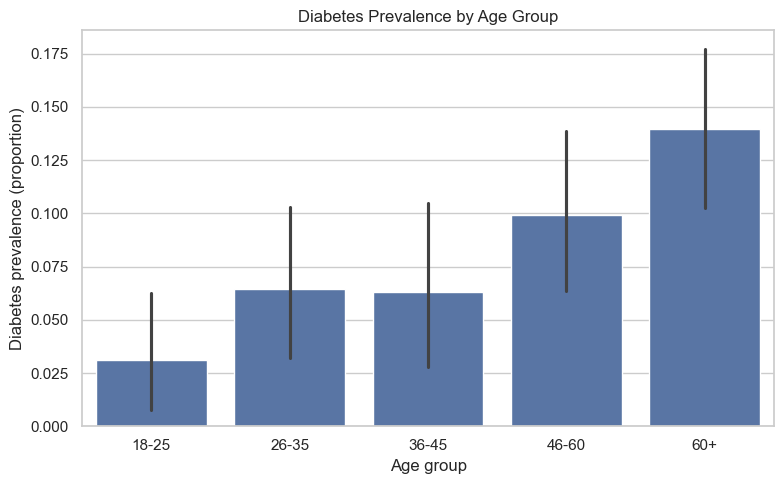

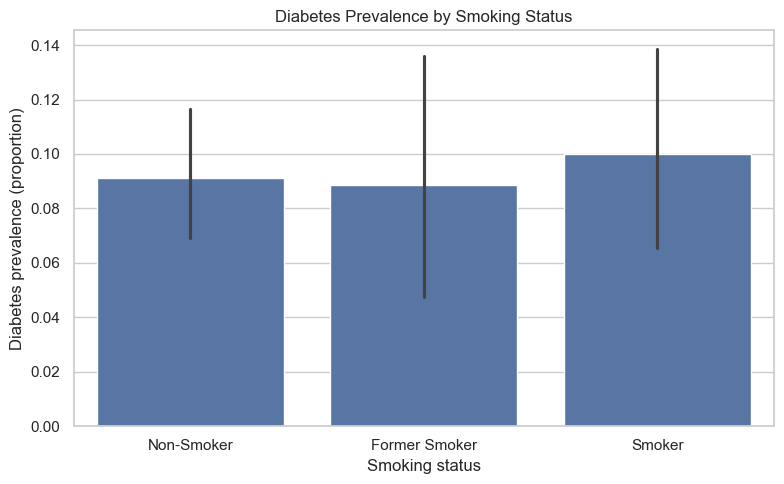

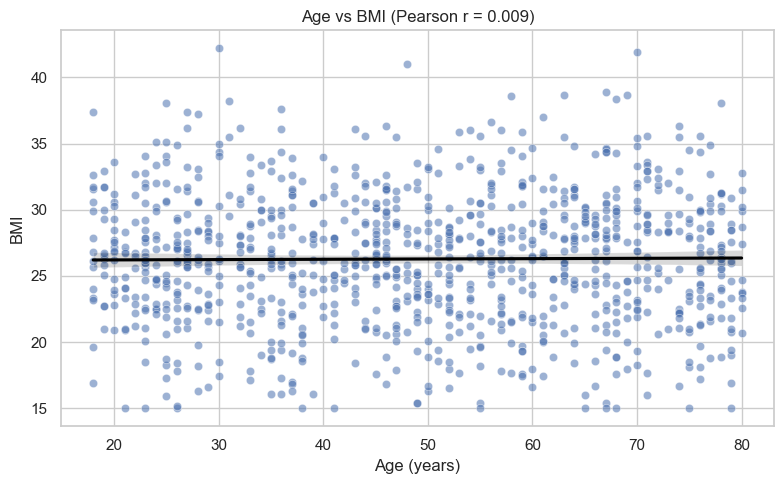

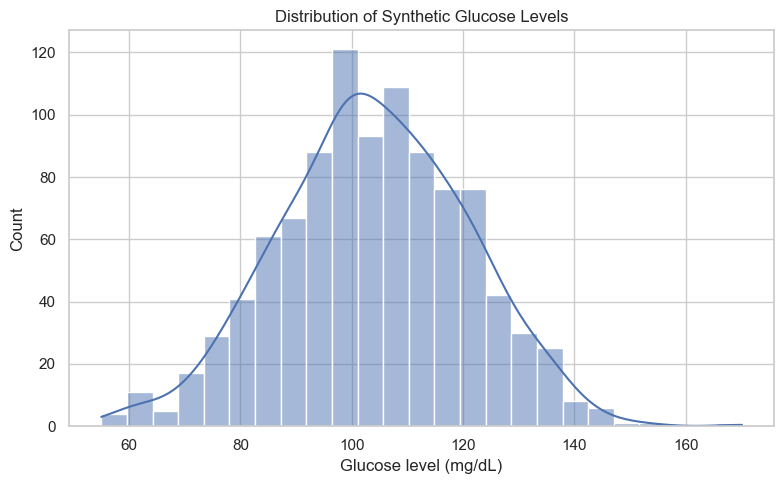

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="age_group", y="diabetes_numeric", order=age_order, errorbar=("ci", 95))
plt.title("Diabetes Prevalence by Age Group")
plt.xlabel("Age group")
plt.ylabel("Diabetes prevalence (proportion)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="smoking_status", y="diabetes_numeric", errorbar=("ci", 95))
plt.title("Diabetes Prevalence by Smoking Status")
plt.xlabel("Smoking status")
plt.ylabel("Diabetes prevalence (proportion)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="bmi", alpha=0.55)
sns.regplot(data=df, x="age", y="bmi", scatter=False, color="black")
plt.title(f"Age vs BMI (Pearson r = {pearson_r:.3f})")
plt.xlabel("Age (years)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["glucose_level"], kde=True)
plt.title("Distribution of Synthetic Glucose Levels")
plt.xlabel("Glucose level (mg/dL)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 13. Consolidated results table
A p-value below 0.05 leads to rejection of the corresponding null hypothesis under the test assumptions. Otherwise, we fail to reject H₀; this does not prove H₀ true. The Pearson correlation test has no single critical value printed here because the correlation coefficient is tested using its associated p-value.

In [12]:
results = pd.DataFrame([
    {"Analysis": "95% CI for mean age", "Statistic": np.nan, "Critical value": t_critical_age, "P-value": np.nan,
     "Decision": "Confidence interval estimation"},
    {"Analysis": "Welch t-test: BMI by diabetes", "Statistic": t_stat, "Critical value": t_crit, "P-value": t_p,
     "Decision": "Reject H0" if t_p < ALPHA else "Fail to reject H0"},
    {"Analysis": "Chi-square: smoking vs diabetes", "Statistic": chi2_stat, "Critical value": chi_critical, "P-value": chi_p,
     "Decision": "Reject H0" if chi_p < ALPHA else "Fail to reject H0"},
    {"Analysis": "ANOVA: diabetes outcome by age group", "Statistic": f_stat, "Critical value": f_critical, "P-value": anova_p,
     "Decision": "Reject H0" if anova_p < ALPHA else "Fail to reject H0"},
    {"Analysis": "Z-test: glucose vs assumed mean 100", "Statistic": z_stat, "Critical value": z_critical, "P-value": z_p,
     "Decision": "Reject H0" if z_p < ALPHA else "Fail to reject H0"},
    {"Analysis": "Pearson correlation: age vs BMI", "Statistic": pearson_r, "Critical value": np.nan, "P-value": pearson_p,
     "Decision": "Reject H0" if pearson_p < ALPHA else "Fail to reject H0"}
])
display(results.round(5))

,Analysis,Statistic,Critical value,P-value,Decision
0,95% CI for mean age,NaN,1.96234,NaN,Confidence interval estimation
1,Welch t-test: BMI by diabetes,3.25771,1.98107,0.00148,Reject H0
2,Chi-square: smoking vs diabetes,0.21374,5.99146,0.89864,Fail to reject H0
3,ANOVA: diabetes outcome by age group,4.37089,2.38088,0.00165,Reject H0
4,Z-test: glucose vs assumed mean 100,7.29594,1.95996,0.00000,Reject H0
5,Pearson correlation: age vs BMI,0.00875,NaN,0.78218,Fail to reject H0


## 14. Final conclusion template
Use the actual calculated values above when completing the report. Do not claim that a relationship exists unless the output supports it.

- The estimated mean age and its 95% confidence interval are reported in Section 6.
- The Welch t-test evaluates whether average BMI differs by diabetes status.
- The chi-square test evaluates the association between smoking category and diabetes status.
- The ANOVA exercise compares mean 0/1 diabetes outcomes across age groups; because the outcome is binary, a categorical test or logistic regression is preferable for formal inference.
- The z-test compares mean synthetic glucose with an explicitly assumed reference mean of 100 mg/dL for demonstration only.
- Covariance and Pearson correlation summarize the relationship between age and BMI.

**Overall limitation:** All records are simulated, the disease probabilities are artificial, and no result from this notebook should be used for medical decisions or to infer real-world causation.

## 15. Export files
Run this cell to save the generated dataset and results table alongside the notebook when using a local Jupyter environment. In Google Colab, files are saved to the session's current working directory and can be downloaded from the Files panel.

In [13]:
df.drop(columns=["diabetes_numeric"], errors="ignore").to_csv("health_dataset.csv", index=False)
results.to_csv("statistical_test_results.csv", index=False)
print("Saved: health_dataset.csv")
print("Saved: statistical_test_results.csv")

Saved: health_dataset.csv
Saved: statistical_test_results.csv
